$$dX_t=-\nabla V(X_T)dt+BdW_t$$

$$X_t=\begin{pmatrix} x_t \\ y_t \end{pmatrix}$$

$$V(X)=\frac{1}{2}m_x^2 x^2 + \frac{1}{2}m_y^2 y^2 + m_{xy}^2xy + \frac{1}{4}\lambda_x x^4 + \frac{1}{4}\lambda_y y^4$$

$$B=\begin{pmatrix}\sigma_x & 0 \\ 0 & \sigma_y \end{pmatrix}$$

In [1]:
using Statistics
import OrdinaryDiffEq as ODE
using Plots
include("../Carleman.jl")

KronAppend (generic function with 1 method)

In [2]:
m2x = 1.0
m2y = 1.0
m2xy = 0.5
lambdax = 0.1
lambday = 0.1
sigmax = 0.5
sigmay = 0.5
x0 = 1.0
y0 = 0.5
tEnd = 0.5

0.5

In [3]:
A = [m2x m2xy; m2xy m2y]
B = [sigmax 0.0; 0.0 sigmay]
vecB = [sigmax, sigmay]
F = [lambdax 0.0 0.0 0.0 0.0 0.0 0.0 0.0; 0.0 0.0 0.0 0.0 0.0 0.0 0.0 lambday]
XIni = [x0, y0]

2-element Vector{Float64}:
 1.0
 0.5

Solve by Carleman

In [4]:
J = 4

4

In [5]:
JMin = 3
JMax = 10
Js = collect(JMin:JMax)
expxCarVariousJ = (Float64)[]
expyCarVariousJ = (Float64)[]

Float64[]

In [6]:
for J in Js
    calC = MakeCalC(A, B, F, J)
    c = MakeVecc(B, J)
    expCalY0 = KronAppend(XIni, J)

    function ECalYODERHS!(du, u, p, t)
        du .= calC * u .+ c
    end

    prob = ODE.ODEProblem(ECalYODERHS!, expCalY0, tEnd)
    sol = ODE.solve(prob, ODE.Tsit5())
    append!(expxCarVariousJ, sol.u[end][1])
    append!(expyCarVariousJ, sol.u[end][2])
end

In [7]:
# From solving SDE
xBench = 2.1736005371366933
yBench = 1.3526649844474572

1.3526649844474572

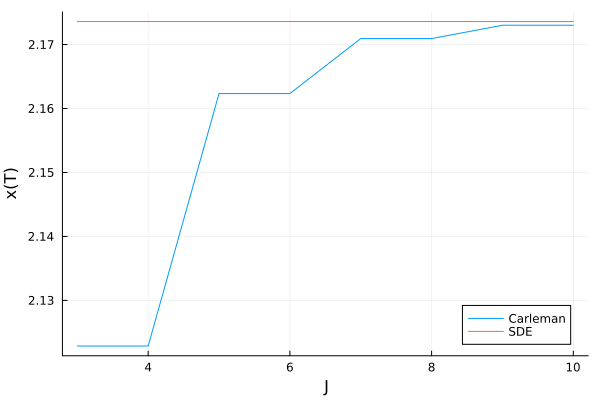

In [8]:
plot(Js, expxCarVariousJ, label="Carleman", xlabel="J", ylabel="x(T)")
plot!(x -> xBench, label="SDE")

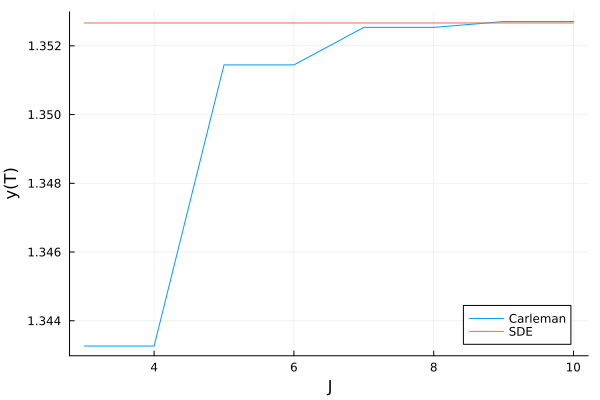

In [9]:
plot(Js, expyCarVariousJ, label="Carleman", xlabel="J", ylabel="y(T)")
plot!(x -> yBench, label="SDE")

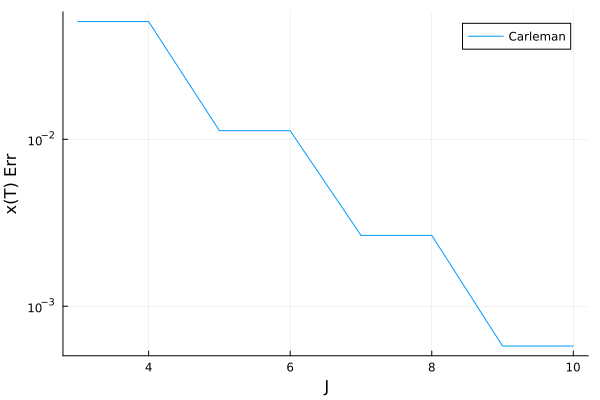

In [10]:
plot(Js, abs.(expxCarVariousJ .- xBench), label="Carleman", xlabel="J", ylabel="x(T) Err", yscale=:log10)

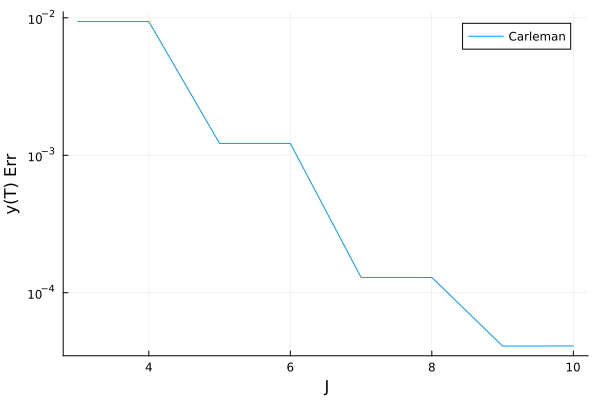

In [11]:
plot(Js, abs.(expyCarVariousJ .- yBench), label="Carleman", xlabel="J", ylabel="y(T) Err", yscale=:log10)